# Project walkthrough — Interpretable Carbon-Aware Electricity Pricing

MIT 15.095 · Clement Docteur & Panle Chen · Low Carbon London 2013 dynamic time-of-use (TOU) trial

**Research question.** Can an interpretable, carbon-aware pricing policy reduce estimated household
electricity emissions relative to the historical TOU tariff while keeping a comparable average announced price?

This notebook is a **read-only tour** of the project. It loads the saved outputs of `run_mvp.py` (JSON, CSV and figures
under `results/` and `carbon_tariff_pipeline/outputs/`). It does **not** retrain or re-optimise anything; the only live
computations are two small illustrations of the price-feasibility rules on toy inputs. It runs in a few seconds with
the project `.venv`.

**Provenance labels used throughout.**

| Label | Meaning |
|---|---|
| 🟦 **Clement — reproduced** | Clement's original implementation; re-run on macOS and reproduced exactly (Steps 2–3) |
| 🟩 **New (MVP)** | Added during the MVP: leak-free features, average-CI metric, IAI trees, pacing rule, budget-aware IAI trees, bill caps |
| 🟨 **Retrospective** | Uses hindsight information (test-period prices, bills or costs); for fairness checks only, **not deployable** |

All emission and bill effects are **model-based counterfactual estimates** (simulated demand × realised grid carbon
intensity), not measured or causal effects. Primary metric: realised **average** carbon intensity (CI);
reduction (%) = 100 × (E_TOU − E_policy) / E_TOU.

## 0. Setup

Run the notebook from the repository root with the project kernel, e.g.
`.venv/bin/python -m jupyter nbconvert --to notebook --execute project_walkthrough.ipynb` or open it in VS Code /
Jupyter and select `.venv`. If the saved outputs are missing, regenerate them once with
`.venv/bin/python run_mvp.py --reproduce` (≈ 11 min).

In [1]:
import json, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_mvp.py").exists())
sys.path.insert(0, str(ROOT / "carbon_tariff_pipeline"))      # Clement's library (lib/), used only for the rule demos
RES, MVP, CLEM = ROOT / "results", ROOT / "results" / "mvp" / "outputs", ROOT / "carbon_tariff_pipeline" / "outputs"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)

def load_json(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))

def fig(path, width=950):
    p = ROOT / path
    display(Image(filename=str(p), width=width) if p.exists() else Markdown(f"*missing: `{path}` — run `run_mvp.py`*"))

required = [MVP / "step3_results_average_mvp.json", MVP / "iai_opt_results_average_mvp.json",
            RES / "pacing" / "pacing_results.json", RES / "affordability" / "affordability_results.json",
            RES / "tables" / "final_comparison.csv", RES / "reproduction" / "reproduction_check.json"]
missing = [str(p.relative_to(ROOT)) for p in required if not p.exists()]
assert not missing, f"missing saved outputs {missing}: run `.venv/bin/python run_mvp.py --reproduce` once"
print("repository:", ROOT.name, "| python", sys.version.split()[0], "| all saved outputs present")

repository: dynamic_pricing_to_reduce_co2 | python 3.12.14 | all saved outputs present


## 1. Workflow overview 🟦

Clement's pipeline schematic (from `carbon_tariff_pipeline/figures/pipeline.png`): next-day carbon-intensity forecast →
demand-response simulator → prescriptive policy tree under an average-price constraint. The MVP keeps this structure and
adds the green items below.

| Step | Script | Origin |
|---|---|---|
| Data build (LCL 2013 household matrix, clusters, ERA5 conditions) | `CVAE_reproduction/scripts/01_build_lcl2013.py`, `03_conditions.py`, `04_clustering.py` | 🟦 |
| 1. Day-ahead CI forecast; 1b. marginal emission factors | `01_ci_forecast.py`, `01b_marginal_emissions.py` | 🟦 |
| 2. Demand-response simulator (+ CVAE sensitivity) | `02_demand_response.py` | 🟦 |
| 3. Menu, exact policy tree, direct optimisation, feasibility rule, budget-aware tree | `03_policy.py` | 🟦 (+ 🟩 opt-in leak-free temperature flag) |
| IAI Optimal Policy Trees | `07_iai_opt.py`, `07_iai_fit.jl` | 🟩 |
| Outputs, sanity checks, reproduction check | `08_mvp_outputs.py`, `09_reproduction_check.py` | 🟩 |
| Pacing rule vs remaining budget as state | `10_pacing_experiment.py` | 🟩 |
| Household-bill caps | `11_bill_constraint.py` | 🟩 |
| Final comparison | `12_final_summary.py` | 🟩 |

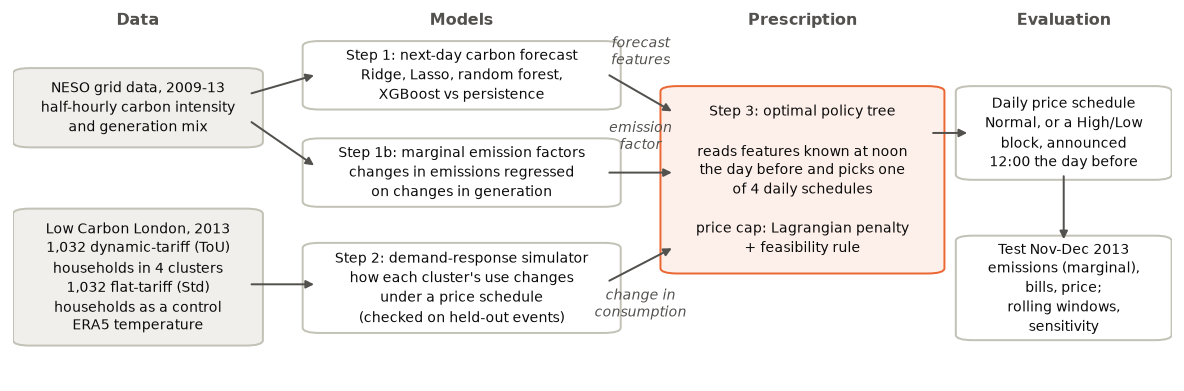

In [2]:
fig("carbon_tariff_pipeline/figures/pipeline.png", 900)

## 2. Data and preprocessing 🟦

* **Low Carbon London** smart meters (8.5 GB csv, 167.9 M rows): kWh per half-hour, GMT timestamps (no DST gaps or
  duplicates). Kept: all **1,032** dynamic-TOU households with > 95 % valid 2013 data and **1,032** flat-tariff (Std)
  control households (seeded sample). 4 behavioural clusters of TOU households.
* **NESO** generation mix and carbon intensity (UTC, 48 half-hours on every 2013 day). **ERA5** temperature
  (reanalysis = realised weather). **Tariff**: the authors' slot-aligned 2013 schedule (Low 3.99 / Normal 11.76 /
  High 67.20 p/kWh).
* **Chronological evaluation**: four rolling 2-month test windows (May–Jun, Jul–Aug, Sep–Oct, Nov–Dec), each validated on
  the 2 preceding months and trained on everything before; main window Nov–Dec.

The data build was re-run on macOS from the raw csv and reproduces Clement's matrix (cluster means within 3.6e-7 kWh).

In [3]:
dq = load_json(RES / "tables" / "data_quality.json")
L = dq["lcl"]
display(pd.Series({
    "raw rows": f'{L["raw_rows"]:,}', "raw households": f'{L["raw_households"]:,}',
    "TOU households kept": f'{L["selected"]["ToU"]:,}', "Std (control) households kept": f'{L["selected"]["Std (flat, random sample, seed 0)"]:,}',
    "duplicate rows averaged (2013)": f'{L["duplicate_rows_2013"]:,}', "off-grid rows dropped (2013)": f'{L["off_grid_rows_dropped_2013"]}',
    "gap-filled share of half-hours": f'{100 * L["gap_fill"]["missing_share_selected"]:.3f} %',
    "NESO 2013 days with 48 half-hours": f'{dq["neso"]["days_2013_with_48_rows"]} / 365',
    "2013 mean carbon intensity": f'{dq["neso"]["ci_2013_gco2_per_kwh"]["mean"]:.0f} g/kWh'}, name="value").to_frame())
display(Markdown("**Chronological split (main analysis)**"))
display(pd.DataFrame(dq["splits"]).set_index("split"))

,value
raw rows,"167,932,474"
raw households,"5,566"
TOU households kept,"1,032"
Std (control) households kept,"1,032"
duplicate rows averaged (2013),"63,608"
off-grid rows dropped (2013),12
gap-filled share of half-hours,0.062 %
NESO 2013 days with 48 half-hours,365 / 365
2013 mean carbon intensity,475 g/kWh


**Chronological split (main analysis)**

,dates,days,High-event days,Low-event days,High slots,Low slots,time-average announced price (p/kWh)
split,,,,,,,
train,2013-01-01 to 2013-08-31,243,53,61,536,1018,13.630
val,2013-09-01 to 2013-10-31,61,13,14,114,150,13.520
test,2013-11-01 to 2013-12-31,61,7,18,90,252,12.795


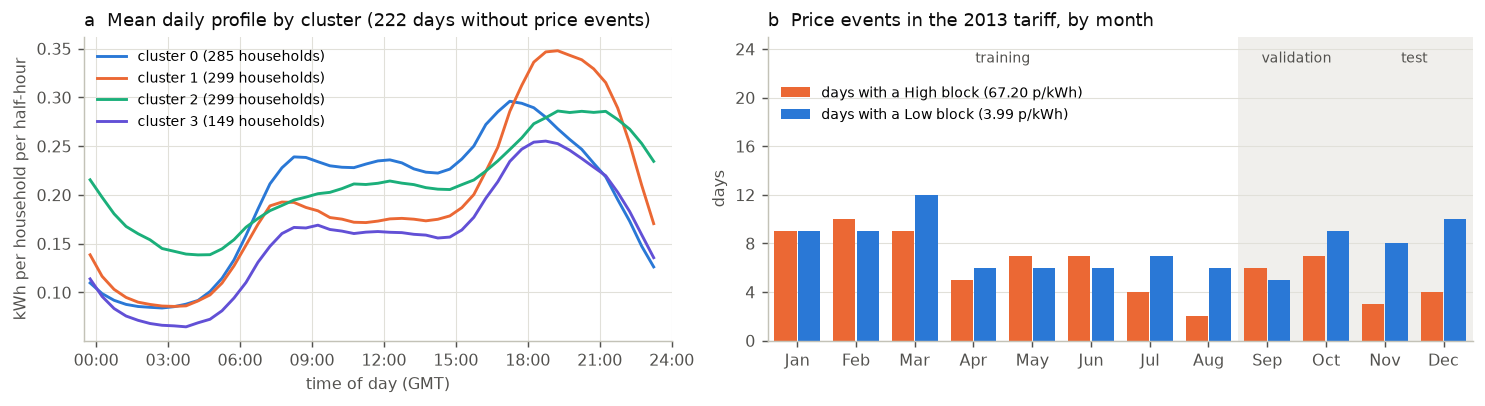

In [4]:
fig("carbon_tariff_pipeline/figures/data_overview.png", 900)

## 3. Carbon-intensity forecasting 🟦

Forecast made at the **12:00 GMT announcement on day d−1** for the 48 half-hours of day d (horizon 12–36 h) from lagged
CI, lagged generation mix and calendar features; monthly expanding refits so every 2013 day has an out-of-sample forecast.
Model choice on Sep–Oct validation MAE. Reproduced exactly on macOS except XGBoost (platform floating point: test MAE
27.23 on Windows vs 27.56 here), which is the selected model.

,val MAE,val RMSE,test MAE,test RMSE
Random forest,24.261,32.141,25.969,34.343
XGBoost,24.003,31.509,27.558,35.459
"Persistence: same slot, latest day",31.561,42.526,28.432,38.582
Flat: mean of last 24 h,31.462,41.151,28.553,38.016
Ridge,25.783,33.203,29.528,37.806
Lasso,25.983,33.461,30.139,38.594
"Persistence: same slot, 7 days ago",37.512,50.482,32.712,43.230


selected on validation: XGBoost


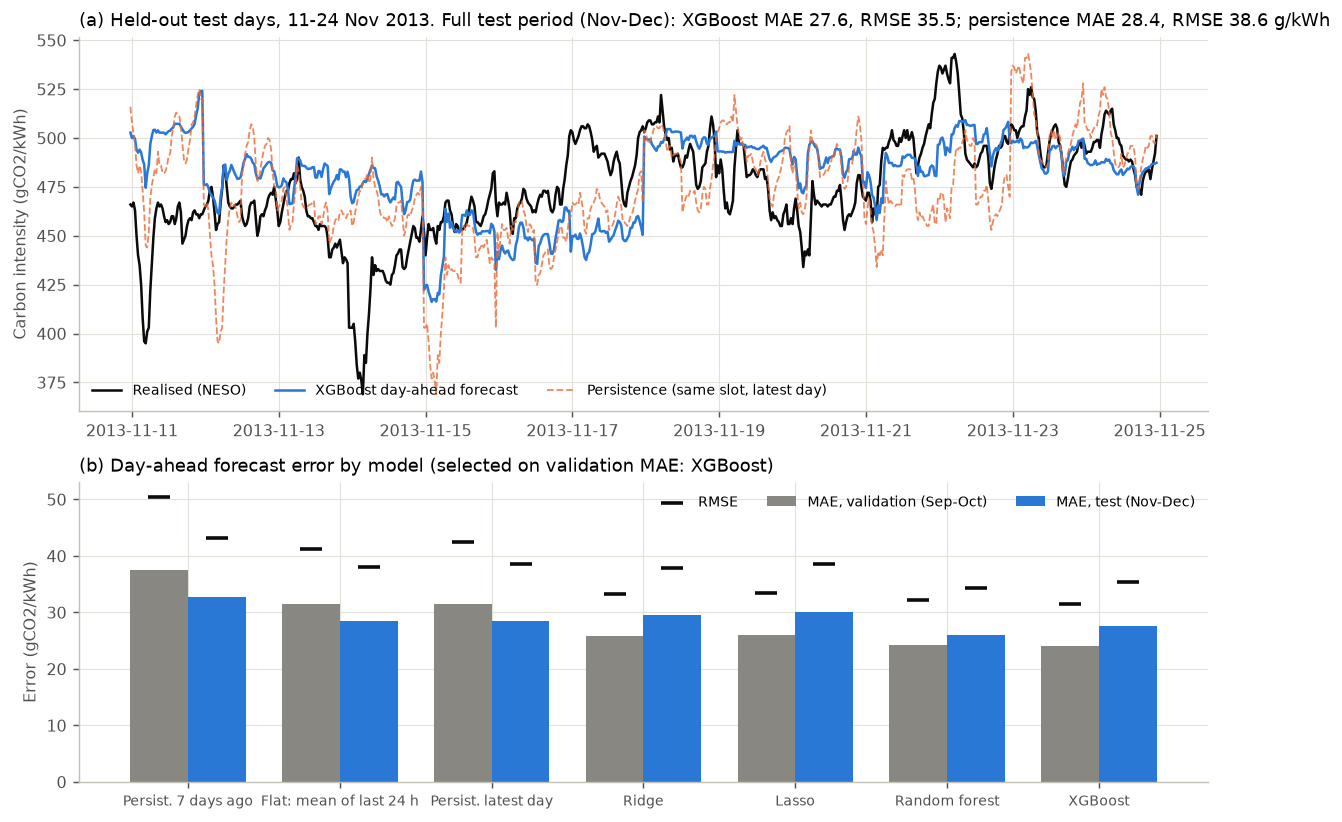

In [5]:
m1 = load_json(MVP / "step1_metrics.json")
tab = pd.DataFrame({m1["labels"][k]: {f"{s} {e}": v[s][e] for s in ("val", "test") for e in ("MAE", "RMSE")}
                    for k, v in m1["metrics"].items()}).T
display(tab.sort_values("test MAE"))
print("selected on validation:", m1["labels"][m1["selected_model"]])
fig("results/figures/fig1_carbon_forecast.png")

*Take-away:* the forecaster beats persistence only modestly on the test window (MAE 27.6 vs 28.4 g/kWh). As later sections
show, forecast quality is not what limits the policies.

## 4. Demand-response model 🟦

Per cluster, a ridge regression of **log(TOU mean / Std mean)** on half-hour × day-type intercepts, temperature and tariff
terms (in-block High/Low effects by time-of-day band, pre-/post-event edges). The flat-tariff households act as a
contemporaneous control (difference-in-differences). Counterfactual demand under a whole-day schedule *z* is
`y(z) = y_obs · exp(m(z) − m(z_TOU))`, so it depends on the **entire** daily schedule (conservation, pre-event dips,
rebound). Fitted on Jan–Oct; the CVAE (Brégère & Bessa; 320 trained checkpoints, not retrained) is kept only as a
sensitivity world because its chronological hold-out performance is poor.

**Assumptions:** coefficients are observational (not causal), identified only for schedule shapes seen in 2013; no fatigue
or income effects.

Held-out Nov-Dec: daily-total MAPE 1.3 %, bias +0.5 %


,obs_mean_kwh,pred_mean_kwh,pred_no_tariff_terms_kwh,n_halfhours
High half-hours,0.247,0.248,0.265,90.0
Normal,0.219,0.220,0.220,2586.0
Low,0.225,0.226,0.210,252.0


,observed %,obs 95% low,obs 95% high,model %,CVAE %
in-block High,-7.706,-8.956,-5.929,-7.454,-1.056
in-block Low,6.544,3.462,9.152,7.722,8.492
2 h before Low,-2.508,-4.175,-0.526,-2.952,0.725
2 h before High,4.209,0.863,8.087,4.520,5.437


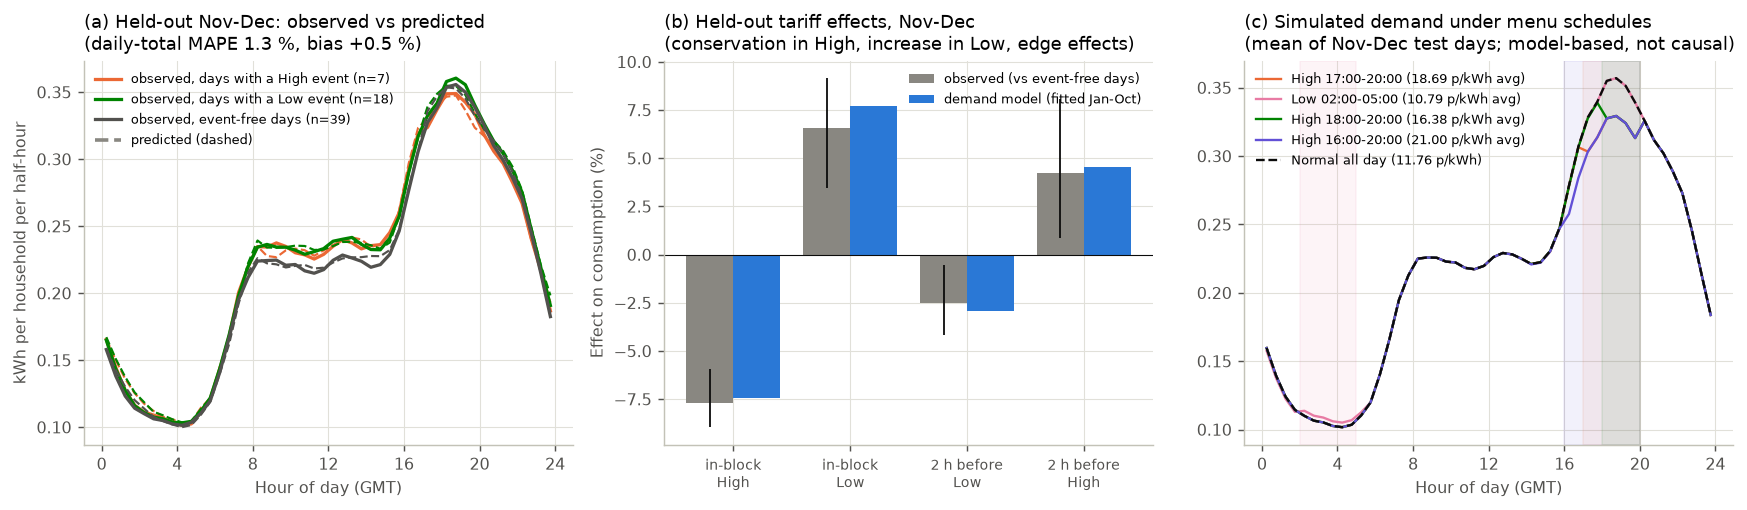

In [6]:
dv = load_json(RES / "tables" / "demand_validation.json")
print(f"Held-out Nov-Dec: daily-total MAPE {dv['daily_total']['mape_pct']:.1f} %, bias {dv['daily_total']['bias_pct']:+.1f} %")
display(pd.DataFrame(dv["by_price_period"]).T.rename(index={"H": "High half-hours", "N": "Normal", "L": "Low"}))
eff = dv["heldout_effects_nov_dec"]
display(pd.DataFrame({k: {"observed %": v["observed_pct"], "obs 95% low": v["observed_ci95"][0], "obs 95% high": v["observed_ci95"][1],
                          "model %": v["main_pct"], "CVAE %": v["cvae_pct"]} for k, v in eff.items()}).T)
fig("results/figures/fig2_demand_response.png")

## 5. Tariff optimisation with policy trees 🟦 + 🟩

**Menu.** Up to 6 daily schedules chosen greedily on *training* days from 98 candidate schedules (single High and/or Low blocks).
**Cost of schedule *z* on day *d*:** `C_d(z) = (1/1000) Σ_t CI_dt · ŷ_dt(z)` (kg CO₂ per household).
**Policy tree.** A prescriptive tree maps decision-time features (forecast-CI summaries, lagged temperature, weekend,
recent consumption) to the schedule minimising summed model-based cost + λ·price; depth (1–3) and λ chosen on validation.
Solvers: Clement's exact solver 🟦 and Interpretable AI's `OptimalTreePolicyMinimizer` 🟩.
**Average-price feasibility rule** 🟦 (proposal): each day, take the first action of the tree leaf's ranking that keeps the
period's time-average announced price target attainable if all remaining days were Normal; an *override* is a day where
the rule replaced the tree's first choice. Target = historical TOU average over train + validation.

🟩 **Leakage fix:** Clement's feature set used the *realised* temperature of day d; the MVP uses the 24 h ending 12:00 on
d−1 (opt-in flag `--temperature lagged`; verified by a perturbation test). The chosen trees never used the leaking feature,
so the headline numbers are unchanged.

In [7]:
s3 = load_json(MVP / "step3_results_average_mvp.json")
print(f"Nov-Dec price target {s3['target_price']:.3f} p/kWh (historical TOU over the test window: {s3['historical_mean_price']['test']:.3f})")
display(pd.DataFrame(s3["menu"]).rename(columns={"name": "menu schedule", "price": "time-average price (p/kWh)"}))
cm = RES / "processed" / "cost_matrix_day_x_action_mvp.parquet"
if cm.exists():
    c = pd.read_parquet(cm)
    display(Markdown("**Day × action cost matrix (first test day)** — `results/processed/`, regenerated by `run_mvp.py`"))
    display(c[c.split == "test"].head(len(s3["menu"]))[["date", "schedule", "avg_announced_price_p_per_kwh", "emissions_eval_kg",
                                                       "emissions_decision_kg", "kwh_pred", "bill_pred_gbp"]])
else:
    print("cost matrix parquet not present (gitignored); run `.venv/bin/python run_mvp.py --stages outputs`")

Nov-Dec price target 13.608 p/kWh (historical TOU over the test window: 12.795)


,menu schedule,time-average price (p/kWh)
0,Normal all day,11.760
1,High 17:00-20:00,18.690
2,Low 02:00-05:00,10.789
3,High 18:00-20:00,16.380
4,High 16:00-20:00,21.000


**Day × action cost matrix (first test day)** — `results/processed/`, regenerated by `run_mvp.py`

,date,schedule,avg_announced_price_p_per_kwh,emissions_eval_kg,emissions_decision_kg,kwh_pred,bill_pred_gbp
1520,2013-11-01,Normal all day,11.760,4.136,4.305,8.994,1.058
1521,2013-11-01,High 17:00-20:00,18.690,4.074,4.237,8.858,1.958
1522,2013-11-01,Low 02:00-05:00,10.789,4.143,4.313,9.008,1.014
1523,2013-11-01,High 18:00-20:00,16.380,4.094,4.260,8.901,1.665
1524,2013-11-01,High 16:00-20:00,21.000,4.059,4.220,8.824,2.198


### 5.1 Main test window (Nov–Dec 2013)

,Policy,Reduction vs TOU (%),95% simulator CI (%),Avg announced price (p/kWh),Within target,Mean bill change (%),Feasibility overrides (of 61),Depth / leaves
0,A. Historical TOU (2013),-0.000,NaN,12.795,n/a (observed),0.000,-,NaN
1,B. Carbon-based heuristic,-0.290,"[-0.42, -0.16]",13.606,yes,4.680,0 (daily rule meets target),NaN
2,C. Direct model-based optimisation,0.841,"[0.75, 0.93]",13.594,yes,14.024,43,NaN
3,D. Policy tree (exact solver),0.763,"[0.67, 0.85]",13.578,yes,8.212,49,2 / 4
4,D'. IAI Optimal Policy Tree,0.796,NaN,13.578,yes,9.513,42,3 / 7
5,Ext. Budget-aware policy tree,0.803,"[0.71, 0.89]",13.575,yes,14.413,3,2 / 4
6,Ref. Oracle (perfect hindsight),0.890,"[0.80, 0.97]",13.551,yes,14.899,n/a (hindsight),NaN


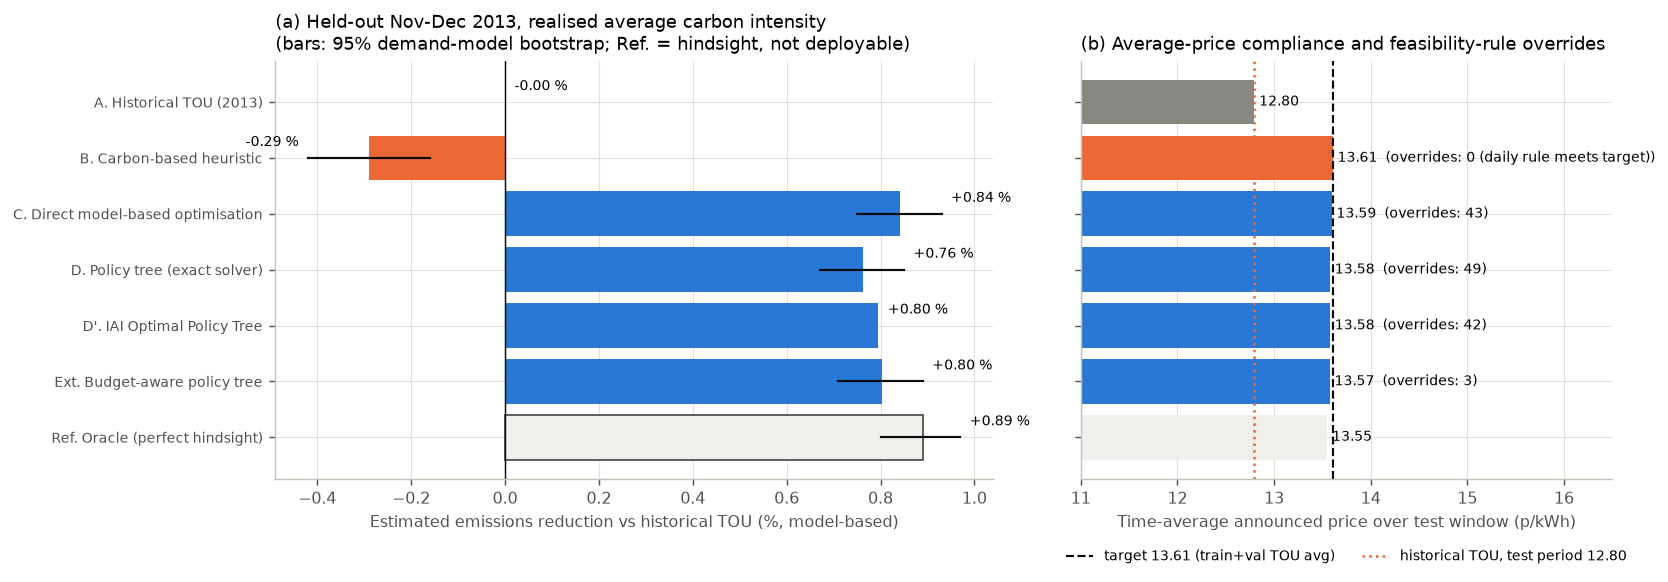

In [8]:
main = pd.read_csv(RES / "tables" / "policy_comparison_main.csv")
display(main[["Policy", "Reduction vs TOU (%)", "95% simulator CI (%)", "Avg announced price (p/kWh)", "Within target",
              "Mean bill change (%)", "Feasibility overrides (of 61)", "Depth / leaves"]])
fig("results/figures/fig3_policy_comparison.png")

*Reading:* the demand-aware policies cut estimated emissions by ~0.8 %; the **carbon-only heuristic increases them**
(Low-price blocks raise consumption). The tree is overridden on 42–49 of 61 days — the feasibility rule, not the tree,
decides most days.

Exact tree chosen on validation (Nov-Dec):
if forecast CI, 16:00-21:00 (g/kWh) <= 475.1:
    if recent consumption (kWh/half-hour) <= 0.1669:
        -> Normal all day  (n=84)
    else:
        -> High 16:00-20:00  (n=33)
else:
    if recent consumption (kWh/half-hour) <= 0.1763:
        -> High 17:00-20:00  (n=59)
    else:
        -> High 16:00-20:00  (n=128)

IAI Optimal Policy Tree chosen on validation (Nov-Dec):
if recent consumption (kWh/half-hour) < 0.1754:
    if temperature, 24 h to 12:00 on d-1 (C) < 13.14:
        if forecast CI, max - min (g/kWh) < 46.13:
            -> Low 02:00-05:00  (n=25)
        else:
            -> High 18:00-20:00  (n=18)
    else:
        if recent consumption (kWh/half-hour) < 0.1711:
            -> Low 02:00-05:00  (n=95)
        else:
            -> High 17:00-20:00  (n=12)
else:
    if recent consumption (kWh/half-hour) < 0.218:
        if forecast CI, 16:00-21:00 (g/kWh) < 475.8:
            -> High 18:00-20:00  (n=15)
        else:
          

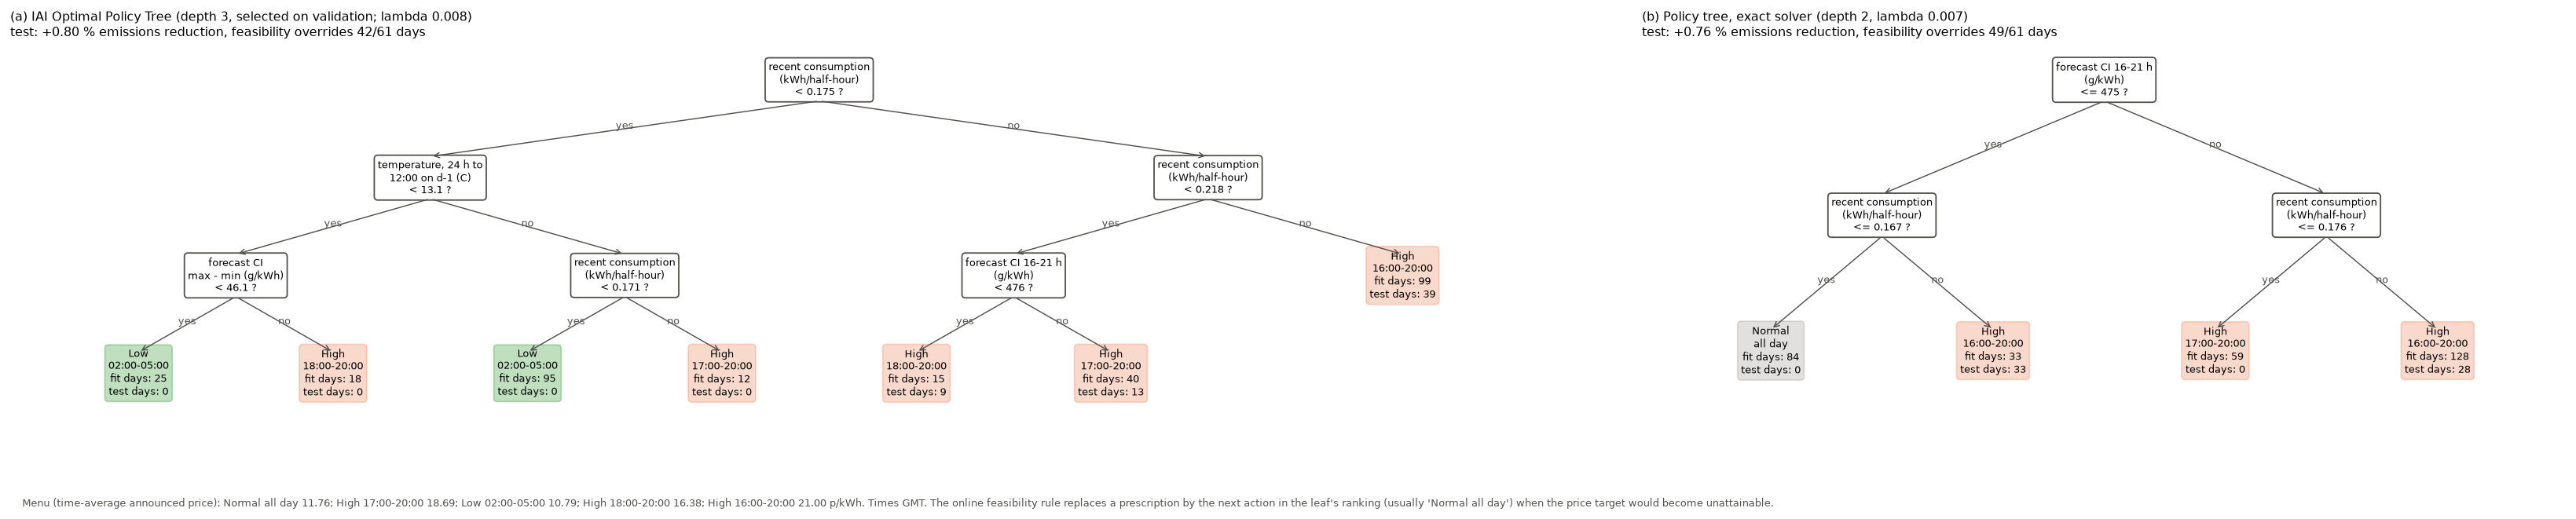

In [9]:
print("Exact tree chosen on validation (Nov-Dec):")
i7 = load_json(MVP / "iai_opt_results_average_mvp.json")
f = i7["folds"]["11"]
print(f["by_depth"]["exact"][str(f["chosen"]["exact"]["depth"])]["text"])
print("IAI Optimal Policy Tree chosen on validation (Nov-Dec):")
print(f["by_depth"]["iai"][str(f["chosen"]["iai"]["depth"])]["text"])
fig("results/figures/fig4_policy_tree.png")

### 5.2 IAI Optimal Policy Trees vs Clement's exact solver 🟩

In [10]:
ive = pd.read_csv(RES / "tables" / "iai_vs_exact.csv")
display(ive[ive["Selected on val"] == "yes"][["Test window", "Solver", "Depth", "Leaves", "Test reduction (%)",
                                               "Overrides (of test days)", "Bill change (%)"]])

,Test window,Solver,Depth,Leaves,Test reduction (%),Overrides (of test days),Bill change (%)
0,May-Jun,Exact tree,1,2,-0.379,0/61,-26.642
3,May-Jun,IAI OPT,1,2,-0.379,0/61,-26.642
6,Jul-Aug,Exact tree,1,2,0.302,0/62,-3.607
9,Jul-Aug,IAI OPT,1,2,0.302,0/62,-3.607
12,Sep-Oct,Exact tree,1,2,0.495,45/61,4.863
15,Sep-Oct,IAI OPT,1,2,0.495,45/61,4.863
19,Nov-Dec,Exact tree,2,4,0.763,49/61,8.212
23,Nov-Dec,IAI OPT,3,7,0.796,42/61,9.513


*Take-away:* the two solvers are effectively equivalent (identical training objective at depth 1, ≤ 0.04 kg apart at
depths 2–3; identical selected trees in 3 of 4 windows). IAI's +0.03 pp in Nov–Dec is inside the simulator uncertainty.

## 6. Reproduction of Clement's results 🟦

Clement's Steps 2–3 were re-run on macOS from his committed Step-1 forecasts and compared value by value with his
committed outputs (`results/reproduction/reproduction_check.md`). His committed files are never overwritten (the MVP
writes to `results/`).

In [11]:
rc = load_json(RES / "reproduction" / "reproduction_check.json")["files"]
rows = []
for k, v in rc.items():
    if isinstance(v, dict) and "values" in v:
        rows.append({"file": k, "numbers compared": v["values"], "mismatches": v["mismatches"], "max abs diff": v["max_abs_diff"]})
    elif isinstance(v, dict):
        d = [x for x in v["max_abs_diff_per_array"].values() if isinstance(x, float)]
        rows.append({"file": k, "numbers compared": f"{len(d)} arrays", "mismatches": "-", "max abs diff": max(d)})
display(pd.DataFrame(rows))
print("Clement's committed average-CI results vs the MVP run (emissions reduction, %):")
display(pd.read_csv(RES / "tables" / "committed_vs_mvp.csv"))

,file,numbers compared,mismatches,max abs diff
0,results/reproduction/outputs/step2_results.json,423,0,0.000e+00
1,results/reproduction/outputs/step3_results.json,1189,0,0.000e+00
2,results/reproduction/outputs/step3_results_average.json,1142,0,0.000e+00
3,results/reproduction/outputs/response_theta.npz,32 arrays,-,1.199e-14
4,results/reproduction/outputs/step3_test_schedules.npz,13 arrays,-,1.110e-16
5,results/reproduction/outputs/step3_test_schedules_average.npz,13 arrays,-,5.551e-17
6,results/reproduction/step1_mac/step1_metrics.json,78,24,7.092e-01
7,results/reproduction/step1_mac/step1b_mef.json,355,0,0.000e+00
8,results/reproduction/step1_mac/ci_forecasts_2013.npz,4 arrays,-,1.922e+01
9,results/reproduction/step1_mac/mef_2013.npz,4 arrays,-,0.000e+00


Clement's committed average-CI results vs the MVP run (emissions reduction, %):


,Policy,"Clement (committed; realised temperature, Windows XGBoost forecast)","MVP (lagged temperature, forecast re-run here)"
0,B. Carbon-based heuristic,-0.176,-0.290
1,C. Direct model-based optimisation,0.841,0.841
2,D. Policy tree (exact solver),0.763,0.763
3,Ext. Budget-aware policy tree,0.803,0.803
4,Ref. Oracle (perfect hindsight),0.890,0.890
5,Policy-tree depth,1.000,2.000


*Reading:* Steps 2–3 reproduce exactly (0 mismatches; arrays to 1e-14). Step 1 differs only for XGBoost (platform), which
changes the carbon heuristic slightly (−0.18 % → −0.29 %) but not the tree, direct optimisation or oracle.

## 7. Budget pacing vs remaining budget as a state variable 🟩

Two responses to "the feasibility rule decides most days":

* **(a) Pacing rule** (`lib/policy.pacing_rule`): cumulative announced prices may run at most *B* ahead of an even spend
  of the target (B chosen on validation; B = ∞ is the original rule).
* **(b) Budget-aware trees** (Clement's design, extended to IAI): the tree sees the **remaining budget per remaining day**
  as a feature, so it decides itself when to spend.

A toy replay first: a policy that always ranks *High 16–20 > High 17–20 > High 18–20 > Normal > Low* (what the Nov–Dec
tree effectively does), under each rule, with the real Nov–Dec menu prices and target. This uses only the rule functions —
no model.

In [12]:
from lib.policy import feasibility_rule, pacing_rule      # Clement's rule and the new pacing rule

menu = s3["menu"]; names = [m["name"] for m in menu]
P = np.tile([m["price"] for m in menu], (61, 1)); T = s3["target_price"]
order = ["High 16:00-20:00", "High 17:00-20:00", "High 18:00-20:00", "Normal all day", "Low 02:00-05:00"]
ranking = [[names.index(n) for n in order]] * 61
out = {}
for label, (acts, adj) in {"original rule": feasibility_rule(ranking, P, T), "pacing rule, B=5": pacing_rule(ranking, P, T, 5.0)}.items():
    high = np.array(["High" in names[a] for a in acts])
    out[label] = {"High-event days": int(high.sum()), "by quarter": "/".join(str(int(high[q].sum())) for q in np.array_split(np.arange(61), 4)),
                  "avg announced price": P[0, acts].mean(), "overrides": adj,
                  "timeline (H = High day)": "".join("H" if h else "." for h in high)}
display(pd.DataFrame(out).T)

,High-event days,by quarter,avg announced price,overrides,timeline (H = High day)
original rule,12,12/0/0/0,13.578,49,HHHHHHHHHHHH.................................................
"pacing rule, B=5",24,7/6/6/5,13.578,61,H.H.H..H.H..H.H..H.H..H.H..H.H..H.H..H.H..H.H..H.H..H.H..H...


The original rule front-loads (events at the start, then Normal days); the pacing rule spreads them. Both meet the target.
This toy replay reproduces the saved Nov–Dec experiment for the exact tree (12 vs 24 High-event days, 12/0/0/0 vs 7/6/6/5,
49 vs 61 overrides), because the real tree prescribes the 4-h evening block on every test day.
The saved experiment results across all four windows:

,policy,rule,mean_reduction_pct,min_reduction_pct,mean_bill_change_pct,mean_overrides,mean_high_first_half_pct
0,exact tree (selected under original rule),original rule,0.295,-0.379,-4.293,23.50,100.000
1,exact tree (selected under original rule),pacing rule,0.325,-0.379,-3.196,30.50,52.083
2,exact tree (re-selected under pacing),pacing rule,0.325,-0.379,-3.196,30.50,52.083
3,iai tree (selected under original rule),original rule,0.303,-0.379,-3.968,21.75,100.000
4,iai tree (selected under original rule),pacing rule,0.326,-0.379,-3.054,29.50,51.000
5,iai tree (re-selected under pacing),pacing rule,0.326,-0.379,-3.054,29.50,51.000
6,exact budget-aware tree,original rule,0.585,0.264,10.241,1.25,22.032
7,exact budget-aware tree,pacing rule,0.587,0.264,10.277,1.25,22.032
8,iai budget-aware tree,original rule,0.610,0.264,10.762,5.00,33.556
9,iai budget-aware tree,pacing rule,0.602,0.264,10.307,8.50,34.384


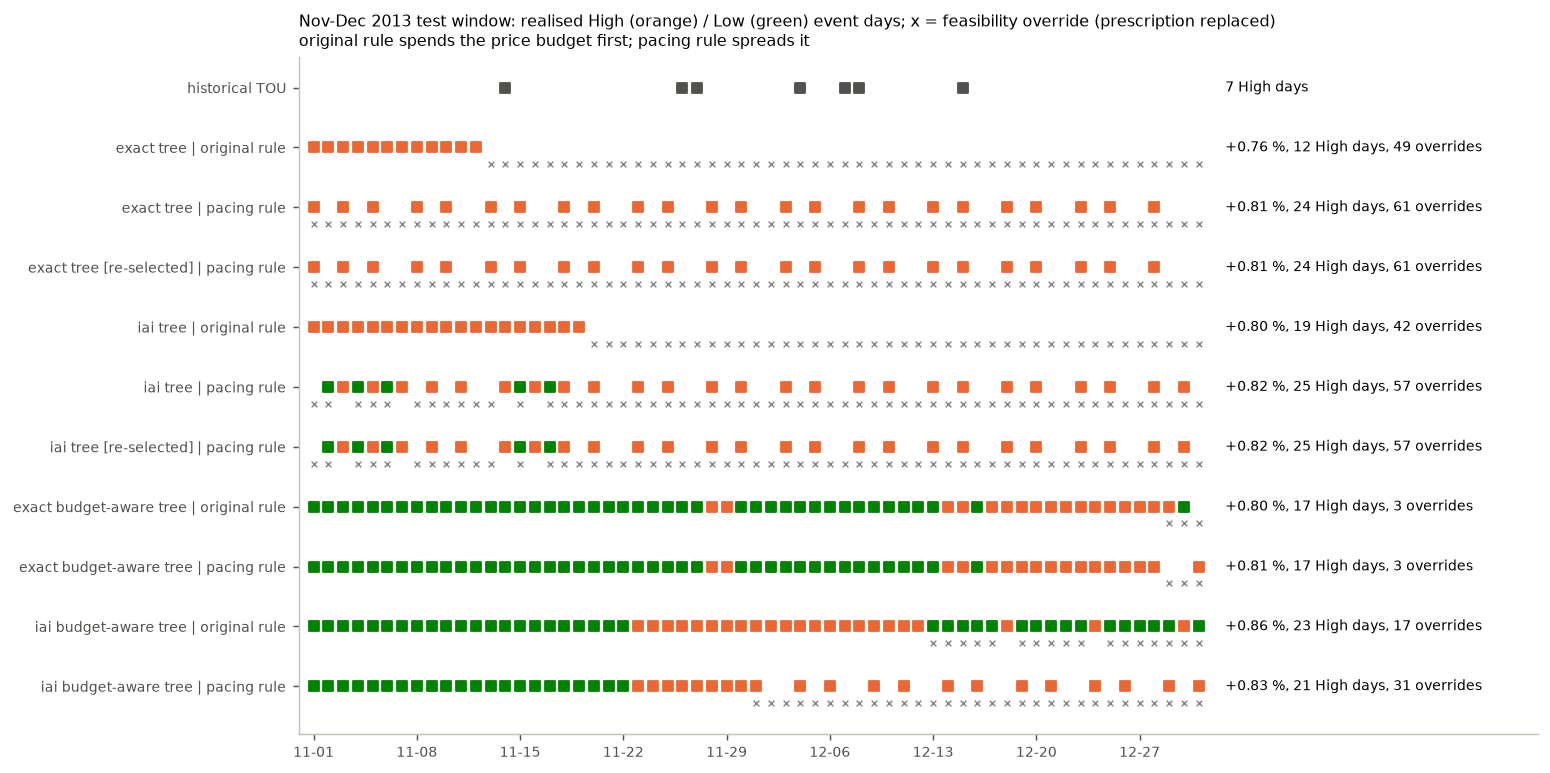

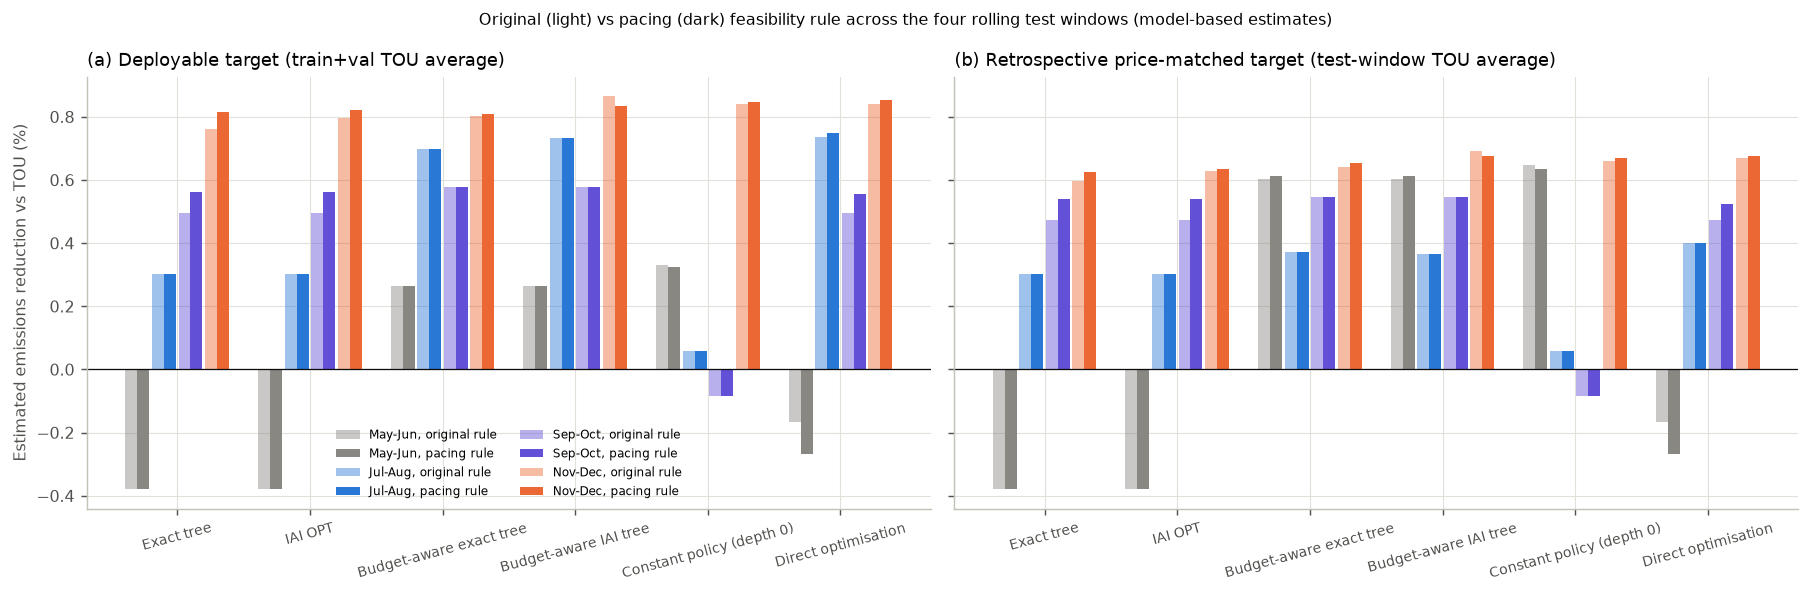

In [13]:
ps = pd.read_csv(RES / "pacing" / "pacing_summary.csv")
display(ps[["policy", "rule", "mean_reduction_pct", "min_reduction_pct", "mean_bill_change_pct", "mean_overrides",
            "mean_high_first_half_pct"]])
fig("results/figures/fig5_pacing_timeline.png")
fig("results/figures/fig6_pacing_rolling.png")

*Take-aways:* pacing spreads events but adds only ≈ +0.03 pp and makes the tree's first choice followed *less* often.
**Budget-aware trees are the real improvement**: positive in all four windows, mean reduction ≈ 0.59–0.61 % vs ≈ 0.30 %
for fixed trees, with few overrides — at the cost of higher bills (≈ +10 %).

## 8. Household affordability constraints 🟩

A second budget is added to the feasibility rule (`lib/policy.multi_budget_rule`): the **predicted price paid** (consumption-
weighted, from the decision-time demand forecast) averaged over the window must stay ≤ (1 + x) × **reference price**, with
x ∈ {0, 5, 10} %. The reference is the historical TOU price paid over **train + validation** — fixed before the test
window. Two variants: *rule only* (post-processing) and *penalty + rule* (tree retrained with a bill penalty μ, chosen on
validation).

,x_pct,variant,mean_reduction_pct,min_reduction_pct,mean_bill_change_pct,mean_bill_change_gbp,windows_sim_within_cap,windows_bill_within_x,mean_overrides,mean_leaves
0,none,unconstrained,0.610,0.264,10.762,7.188,-,-,5.00,2.50
1,0,rule only,0.462,0.183,3.696,2.036,3/4,1/4,12.75,2.00
2,0,penalty + rule,0.438,-0.109,0.384,-0.460,3/4,1/4,5.75,3.00
3,5,rule only,0.568,0.264,8.613,5.518,3/4,1/4,8.00,2.50
4,5,penalty + rule,0.585,0.228,7.344,4.697,4/4,1/4,0.50,3.25
5,10,rule only,0.610,0.264,10.762,7.188,4/4,1/4,5.00,2.50
6,10,penalty + rule,0.614,0.264,8.919,5.989,4/4,2/4,5.00,2.50


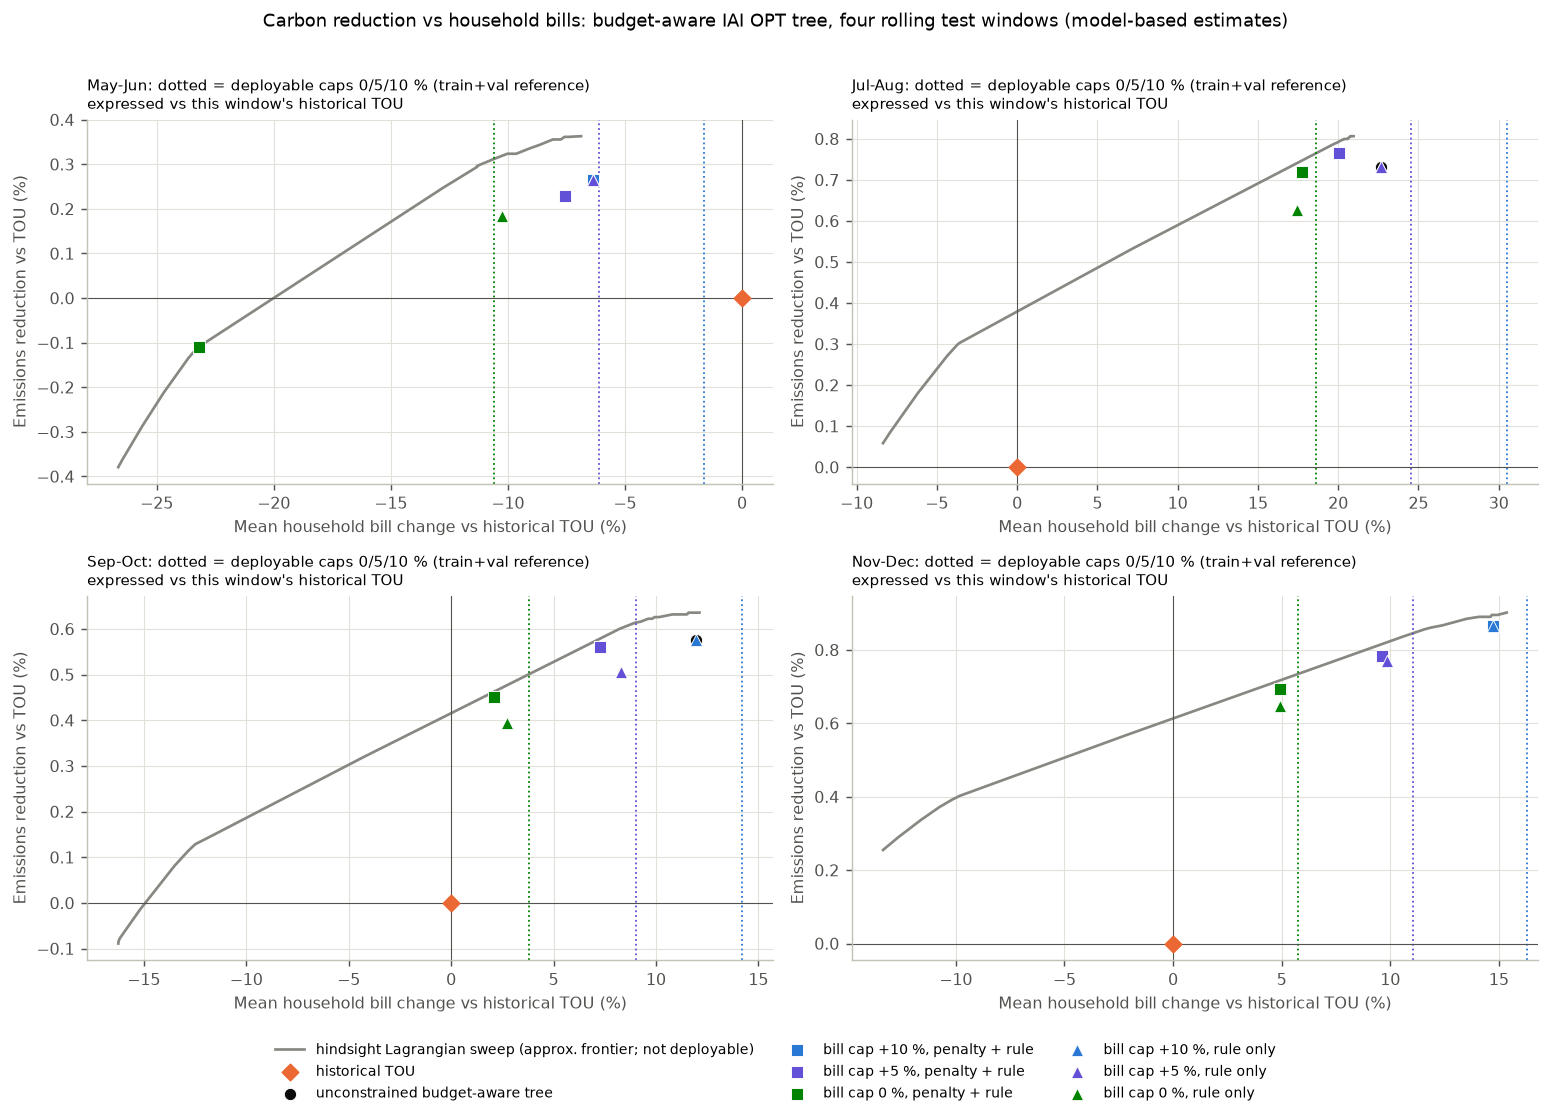

In [14]:
af = pd.read_csv(RES / "affordability" / "affordability_summary.csv")
display(af[af.solver == "iai"][["x_pct", "variant", "mean_reduction_pct", "min_reduction_pct", "mean_bill_change_pct",
                                 "mean_bill_change_gbp", "windows_sim_within_cap", "windows_bill_within_x", "mean_overrides", "mean_leaves"]])
fig("results/figures/fig7_carbon_vs_bills.png")

**Is the cap satisfied?** (i) The *predicted* price paid always is (by construction); (ii) the *simulated* price paid is
in nearly all cases (misses ≤ 0.07 p/kWh = forecast error); (iii) the bill **relative to the historical TOU in the same
test window** is within x in only 1–2 of 4 windows — because the historical TOU's own price paid swings with the trial's
event schedule (shown below). That comparison cannot be guaranteed by any deployable rule.

In [15]:
afr = load_json(RES / "affordability" / "affordability_results.json")
display(pd.DataFrame({r["label"]: {"reference price paid (train+val)": r["pi_ref_trainval"],
                                   "historical TOU price paid (test window)": r["pi_ref_test_historical"]}
                      for r in afr["folds"].values()}).T)

,reference price paid (train+val),historical TOU price paid (test window)
May-Jun,13.875,15.518
Jul-Aug,14.429,12.162
Sep-Oct,13.851,13.341
Nov-Dec,13.748,13.002


## 9. Final comparison and primary candidate 🟩

**Primary candidate:** budget-aware IAI Optimal Policy Tree with a **+5 % bill cap (penalty + feasibility rule)**.
Chosen as a reasonable carbon–affordability trade-off — not a statistically or universally optimal policy.

**Emissions reduction vs historical TOU (%)**

window,May-Jun,Jul-Aug,Sep-Oct,Nov-Dec,mean
policy,,,,,
Historical TOU,0.000,0.000,0.000,0.000,0.000
Carbon heuristic,-0.578,0.323,-0.294,-0.290,-0.210
"Policy tree, exact solver (Clement)",-0.379,0.302,0.495,0.763,0.295
IAI OPT,-0.379,0.302,0.495,0.796,0.303
Direct optimisation,-0.167,0.736,0.495,0.841,0.477
Budget-aware IAI OPT (no bill cap),0.264,0.732,0.577,0.865,0.610
"Budget-aware IAI OPT, bill cap +5 % (penalty + rule) [PRIMARY]",0.228,0.767,0.561,0.783,0.585
Oracle (hindsight; reference only),0.363,0.805,0.621,0.890,0.670


**Mean household bill change vs historical TOU (%)**

window,May-Jun,Jul-Aug,Sep-Oct,Nov-Dec,mean
policy,,,,,
Historical TOU,0.000,0.000,0.000,0.000,0.000
Carbon heuristic,-7.333,19.734,5.292,4.680,5.593
"Policy tree, exact solver (Clement)",-26.642,-3.607,4.863,8.212,-4.293
IAI OPT,-26.642,-3.607,4.863,9.513,-3.968
Direct optimisation,-23.746,19.250,4.863,14.024,3.598
Budget-aware IAI OPT (no bill cap),-6.361,22.698,11.978,14.732,10.762
"Budget-aware IAI OPT, bill cap +5 % (penalty + rule) [PRIMARY]",-7.566,20.028,7.275,9.638,7.344
Oracle (hindsight; reference only),-6.874,20.962,11.881,14.899,10.217


**Average announced price (p/kWh)**

window,May-Jun,Jul-Aug,Sep-Oct,Nov-Dec,mean
policy,,,,,
Historical TOU,15.002,12.278,13.520,12.795,13.399
Carbon heuristic,13.606,14.092,13.606,13.606,13.728
"Policy tree, exact solver (Clement)",10.789,11.760,13.578,13.578,12.426
IAI OPT,10.789,11.760,13.578,13.578,12.426
Direct optimisation,11.517,14.054,13.578,13.594,13.186
Budget-aware IAI OPT (no bill cap),13.554,14.065,13.601,13.579,13.700
"Budget-aware IAI OPT, bill cap +5 % (penalty + rule) [PRIMARY]",13.582,14.070,13.578,13.578,13.702
Oracle (hindsight; reference only),13.618,14.082,13.560,13.551,13.703


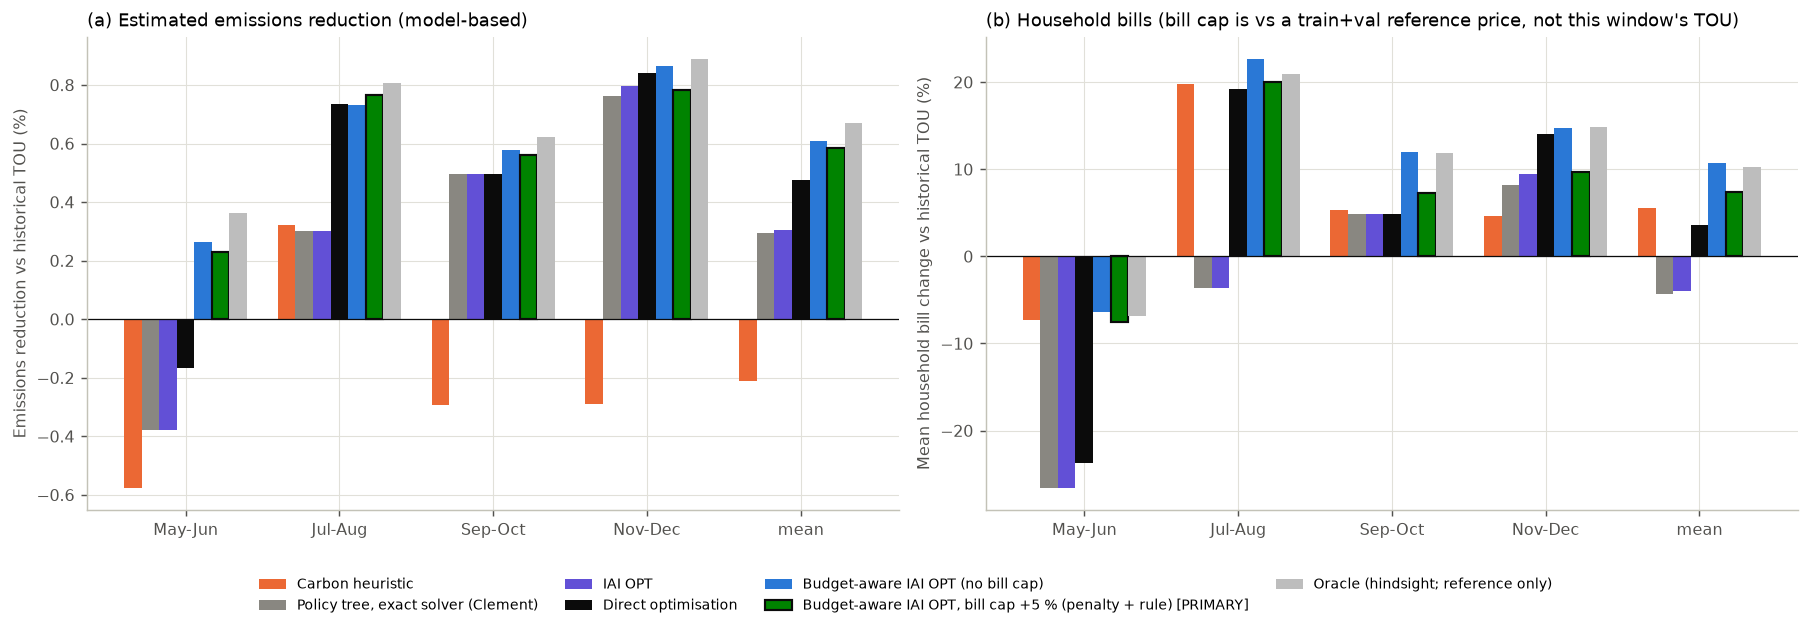

In [16]:
fc = pd.read_csv(RES / "tables" / "final_comparison.csv")
order = list(dict.fromkeys(fc.policy))
for col, title in (("reduction_pct", "Emissions reduction vs historical TOU (%)"), ("bill_change_pct", "Mean household bill change vs historical TOU (%)"),
                   ("avg_announced_price", "Average announced price (p/kWh)")):
    t = fc.pivot_table(index="policy", columns="window", values=col, sort=False).reindex(order)[["May-Jun", "Jul-Aug", "Sep-Oct", "Nov-Dec"]]
    t["mean"] = t.mean(axis=1)
    display(Markdown(f"**{title}**")); display(t)
fig("results/figures/fig8_final_comparison.png")

In [17]:
prim = fc[fc.policy.str.contains("PRIMARY")].set_index("window")
display(Markdown("**Primary candidate — constraint checks per window**"))
display(prim[["price_target", "avg_announced_price", "cap", "pred_price_paid", "sim_price_paid", "pred_within_cap",
              "sim_within_cap", "bill_within_5pct_of_historical", "overrides", "depth", "leaves"]])
for m, r in afr["folds"].items():
    print(f"--- {r['label']} primary tree:")
    print(r["policies"]["iai|penalty + rule|5%"]["main"]["tree_text"])

**Primary candidate — constraint checks per window**

,price_target,avg_announced_price,cap,pred_price_paid,sim_price_paid,pred_within_cap,sim_within_cap,bill_within_5pct_of_historical,overrides,depth,leaves
window,,,,,,,,,,,
May-Jun,13.630,13.582,14.569,14.323,14.303,True,True,True,0,3.0,7.0
Jul-Aug,14.092,14.070,15.150,14.672,14.763,True,True,False,1,1.0,2.0
Sep-Oct,13.630,13.578,14.543,14.424,14.464,True,True,False,1,1.0,2.0
Nov-Dec,13.608,13.578,14.436,14.366,14.328,True,True,False,0,1.0,2.0


--- May-Jun primary tree:
if remaining budget per remaining day (p/kWh above Normal) < 4:
    if remaining budget per remaining day (p/kWh above Normal) < 1.75:
        if temperature, 24 h to 12:00 on d-1 (C) < 0.1324:
            -> High 18:00-20:00  (n=45)
        else:
            -> Low 02:00-05:00  (n=555)
    else:
        if recent consumption (kWh/half-hour) < 0.2215:
            -> Low 02:00-05:00  (n=46)
        else:
            -> High 18:00-20:00  (n=194)
else:
    if remaining budget per remaining day (p/kWh above Normal) < 7.25:
        if weekend or holiday < 0.5:
            -> High 18:00-20:00  (n=83)
        else:
            -> High 13:00-16:00  (n=37)
    else:
        -> High 13:00-16:00  (n=120)

--- Jul-Aug primary tree:
if remaining budget per remaining day (p/kWh above Normal) < 4:
    -> Normal all day  (n=1267)
else:
    -> High 17:00-20:00  (n=362)

--- Sep-Oct primary tree:
if remaining budget per remaining day (p/kWh above Normal) < 2.5:
    -> Normal al

*Why this policy:* it keeps ≈ 96 % of the uncapped budget-aware tree's mean reduction (0.585 % vs 0.610 %), lowers the mean
bill increase from +10.8 % to +7.3 %, meets the price target and its (pre-set-reference) bill cap in every window, and the
feasibility rule almost never intervenes. In three windows it is a one-split rule on the remaining budget — readable, but
note it does **not** use the day-ahead carbon forecast to time events; its carbon benefit comes from evening conservation.

## 10. Retrospective sensitivity analyses 🟨 (not deployable)

These use test-period information and are fairness checks only.

In [18]:
sp = pd.read_csv(RES / "tables" / "sensitivity_price_target.csv")
display(Markdown("**Price target (Nov–Dec; emissions reduction %)** — the 12.795 row uses the test window's own historical price"))
display(sp)
afm = [{"window": r["label"], "cap": f"{int(100 * p['x'])} %",
        "reduction (%)": p["matched"].get("emissions_reduction_pct"), "bill change vs historical TOU (%)": p["matched"].get("bill_change_mean_pct"),
        "within cap": p["matched"].get("bill_within_x_vs_historical")}
       for r in afr["folds"].values() for k, p in r["policies"].items() if k.startswith("iai|penalty")]
display(Markdown("**Bill cap relative to each window's own historical TOU (IAI, penalty + rule)**"))
display(pd.DataFrame(afm).pivot_table(index="window", columns="cap", values="reduction (%)", sort=False))

**Price target (Nov–Dec; emissions reduction %)** — the 12.795 row uses the test window's own historical price

,Constraint,Role,B. Carbon-based heuristic,D. Policy tree (exact solver),C. Direct model-based optimisation,Ref. Oracle (perfect hindsight),Ext. Budget-aware policy tree
0,Time-average price <= 13.608 (Jan-Oct historical TOU; main),PRIMARY: train+val historical TOU average (deployable),-0.289827827164089,0.763,0.841,0.890,0.803
1,"Time-average price <= 12.795 (historical TOU, test period)",RETROSPECTIVE fairness check: uses the test period's own historical price (n...,-0.20478969334740332,0.613,0.670,0.693,0.640
2,Time-average price <= 13.517 (full-year 2013 TOU in Tariffs.xlsx; proposal),"proposal reference (full-year 2013, Tariffs.xlsx)",-0.4197937186427797,0.750,0.815,0.881,0.789
3,Time-average price <= 14.228 (flat Std tariff),flat Std tariff (sensitivity),0.06877924317002929,0.884,0.935,1.022,0.930
4,Average price paid <= 13.784 (Jan-Oct historical level),cap on consumption-weighted price paid instead of time-average,n/a (rule defined for time-average only),0.669,0.682,0.729,0.684


**Bill cap relative to each window's own historical TOU (IAI, penalty + rule)**

cap,0 %,5 %,10 %
window,,,
May-Jun,-0.109,0.228,0.264
Jul-Aug,0.362,0.453,0.551
Sep-Oct,0.363,0.480,0.561
Nov-Dec,0.585,0.677,0.753


## 11. Main findings, limitations and discussion points

**Findings (model-based).**
1. Demand-aware policies reduce estimated household emissions vs the 2013 TOU at a comparable average announced price, but
   the effect is small (≈ 0.2–0.8 % over two months; 0.5–2.3 kg CO₂ per household for the primary policy).
2. The carbon-only heuristic increases emissions — demand response matters more than carbon timing.
3. IAI and the exact solver are equivalent; making the tree **budget-aware** is what makes it robust across seasons.
4. A +5 % bill cap costs little carbon; bill increases are transfers of roughly £4,800–8,600 per tonne avoided, so
   affordability is mainly distributional.

**Limitations.** Observational demand response (no fatigue / income effects; cluster 3 has very large effects);
bootstrap only for Nov–Dec; hyper-parameters selected on single 2-month windows; trees rarely use carbon features; one year,
one city; ERA5 is reanalysis.

**To discuss (see `TEAM_HANDOFF.md`).** Headline metric (average vs marginal CI); bill-cap reference (train+val TOU vs flat
tariff vs rebate); how strongly to word "carbon-aware"; whether to extend uncertainty analysis; updating
`final_report/main.tex`.

## 12. Optional: automated checks
Runs `tests/run_checks.py` (≈ 10 s): rule unit tests, preservation of Clement's outputs, exact reproduction, constraint compliance, consistency.

In [19]:
r = subprocess.run([sys.executable, str(ROOT / "tests" / "run_checks.py")], cwd=ROOT, capture_output=True, text=True)
print(r.stdout if r.returncode == 0 else r.stdout + r.stderr)

[PASS] pacing_rule(borrow=inf) == feasibility_rule (200 random rankings)
[PASS] multi_budget_rule(single budget) == feasibility_rule (200 random rankings)
[PASS] pacing_rule(borrow=0) keeps the cumulative pace and the period target
[PASS] multi_budget_rule satisfies both budgets (200 random rankings)
[PASS] raw-data lookup ($CARBON_RAW_DIR > repo root > parent; LCL_Data/ accepted) in lib/common, lcl_data, run_mvp -- this machine: {'NESO': 'df_fuel_ckan.csv', 'tariffs': 'dynamic_pricing_to_reduce_co2/Tariffs.xlsx'}, LCL LCL_Data/CC_LCL-FullData.csv
[PASS] a. Clement's ORIGINAL results (6c22f28): every value preserved (additions allowed) -- 2330 files, 3,984,557 values compared; changed []; removed []; additions: 21 (mef_2013.npz:realised_netload, step1b_mef.json:/checks/mean_test/mef_netload, step1b_mef.json:/checks/netload_vs_hourly_test_corr, step1b_mef.json:/netload_2013, step1b_mef.json:/out_of_sample_r2_dE, step3_results_average.json:/rolling/11/matched_paced_adjustments ...)
[PASS